In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
titanic_df = pd.read_csv("data/titanic.csv")

titanic_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [3]:
titanic_df.describe()

,Survived,Pclass,Age,SibSp,PaCh,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [4]:
features = titanic_df.drop(columns=["Survived", "Name"])

target = titanic_df["Survived"]

X = features.copy()

y = target.copy()

In [5]:
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,male,22.0,1,0,7.2500
1,1,female,38.0,1,0,71.2833
2,3,female,26.0,0,0,7.9250
3,1,female,35.0,1,0,53.1000
4,3,male,35.0,0,0,8.0500


In [6]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [7]:
X['Sex'] = X['Sex'].map({"female": 0, "male": 1})

In [8]:
X['Sex']

0      1
1      0
2      0
3      0
4      1
      ..
882    1
883    0
884    0
885    1
886    1
Name: Sex, Length: 887, dtype: int64

In [9]:
X

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,1,22.0,1,0,7.2500
1,1,0,38.0,1,0,71.2833
2,3,0,26.0,0,0,7.9250
3,1,0,35.0,1,0,53.1000
4,3,1,35.0,0,0,8.0500
...,...,...,...,...,...,...
882,2,1,27.0,0,0,13.0000
883,1,0,19.0,0,0,30.0000
884,3,0,7.0,1,2,23.4500
885,1,1,26.0,0,0,30.0000


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=20, stratify=y)

In [11]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [12]:
prediction = pipeline.predict(X_test)

accuracy = accuracy_score(
    y_test,
    prediction
)
print("Logistic Accuracy", accuracy)

Logistic Accuracy 0.7790262172284644


In [13]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82       164
           1       0.72      0.71      0.71       103

    accuracy                           0.78       267
   macro avg       0.77      0.77      0.77       267
weighted avg       0.78      0.78      0.78       267



In [14]:
confusion_matrix(y_test, prediction)

array([[135,  29],
       [ 30,  73]])

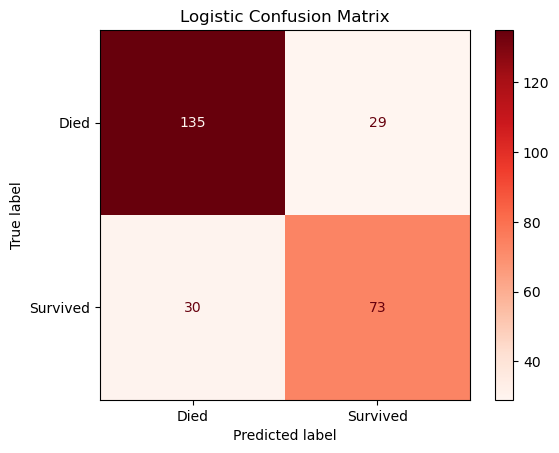

In [15]:
lr_display = ConfusionMatrixDisplay(confusion_matrix(y_test, prediction), display_labels=["Died", "Survived"])
lr_display.plot(cmap=plt.cm.Reds)
plt.title("Logistic Confusion Matrix")
plt.savefig("images/logistic_confusion_matrix.png", bbox_inches="tight")
plt.show()

# Tuning the model 

In [16]:
log_params = ({
    "max_iter": [300, 500, 900],
    "solver": ["lbfgs", "liblinear"],
    "C": [0.01, 0.1, 1, 10, 100]
})
log_grid = GridSearchCV(
    LogisticRegression(random_state=10),
    log_params,
    cv=5,
    scoring="accuracy"
)
log_grid.fit(X_train, y_train)

,estimator,LogisticRegre...ndom_state=10)
,param_grid,"{'C': [0.01, 0.1, ...], 'max_iter': [300, 500, ...], 'solver': ['lbfgs', 'liblinear']}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [17]:
print(log_grid.best_estimator_)
print(log_grid.best_score_)

LogisticRegression(C=10, max_iter=300, random_state=10, solver='liblinear')
0.817741935483871


In [18]:
best_log_model = log_grid.best_estimator_

log_pred = best_log_model.predict(X_test)

log_accuracy = accuracy_score(
    y_test,
    log_pred
)
print("Tuned Logistic Accuracy", log_accuracy)

Tuned Logistic Accuracy 0.7790262172284644


In [19]:
confusion_matrix(y_test, log_pred)

array([[135,  29],
       [ 30,  73]])

## Prediction Function

In [20]:
input_data = pd.DataFrame([[3, 0, 25.0, 0, 0, 12]], columns=X.columns)
pipeline.predict(input_data)

array([1])

# DecisionTree Model

In [21]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=5)

tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,5
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [22]:
tree_pred = tree_model.predict(X_test)

tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)
print("Tree Accuracy", tree_accuracy)

Tree Accuracy 0.8314606741573034


In [23]:
print(classification_report(y_test, tree_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87       164
           1       0.81      0.74      0.77       103

    accuracy                           0.83       267
   macro avg       0.83      0.81      0.82       267
weighted avg       0.83      0.83      0.83       267



In [24]:
confusion_matrix(y_test, tree_pred)

array([[146,  18],
       [ 27,  76]])

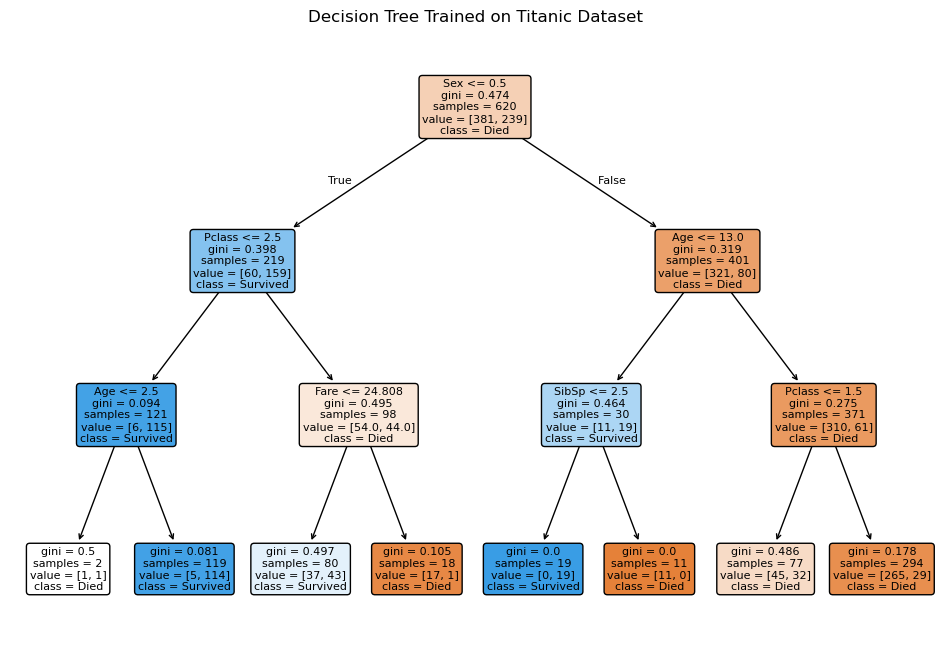

In [25]:
plt.figure(figsize=(12, 8))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=["Died", "Survived"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree Trained on Titanic Dataset")
plt.savefig("images/decision_tree_plot.png", bbox_inches="tight")
plt.show()

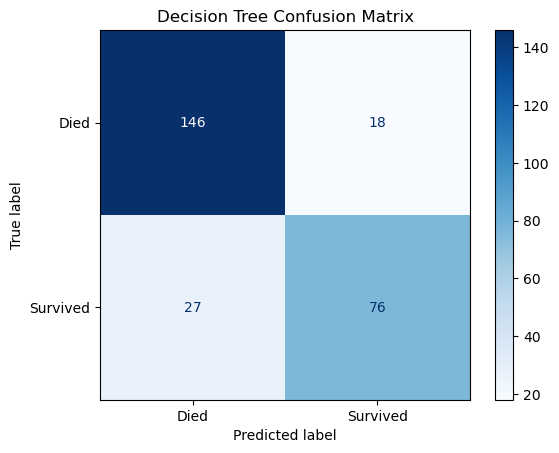

In [26]:
tree_display = ConfusionMatrixDisplay(confusion_matrix(y_test, tree_pred), display_labels=["Died", "Survived"])
tree_display.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.savefig("images/decision_tree_confusion_matrix.png", bbox_inches="tight")
plt.show()

## Hyperparameter Tuning

In [27]:
tree_params = ({
    "max_depth":[2, 3, 5, 7, 10],
    "min_samples_leaf": [1, 3, 5],
    "min_samples_split": [2, 5, 7],
    "criterion": ["gini", "entropy"]
})
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=5),
    tree_params,
    cv=5,
    scoring="accuracy"
)
tree_grid.fit(X_train, y_train)

,estimator,DecisionTreeC...andom_state=5)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 3, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [28]:
print(tree_grid.best_params_)
print(tree_grid.best_score_)

{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 3, 'min_samples_split': 2}
0.8258064516129032


In [29]:
best_tree_model = tree_grid.best_estimator_

tree_prediction = best_tree_model.predict(X_test)

tuned_tree_accuracy = accuracy_score(
    y_test,
    tree_prediction
)
print("Tuned Tree Accuracy", tuned_tree_accuracy)

Tuned Tree Accuracy 0.7677902621722846


In [30]:
print(classification_report(y_test, tree_prediction))

              precision    recall  f1-score   support

           0       0.84      0.77      0.80       164
           1       0.68      0.77      0.72       103

    accuracy                           0.77       267
   macro avg       0.76      0.77      0.76       267
weighted avg       0.78      0.77      0.77       267



In [31]:
confusion_matrix(y_test, tree_prediction)

array([[126,  38],
       [ 24,  79]])

## Random Forest Model

In [32]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=40
)
forest_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
forest_pred = forest_model.predict(X_test)

forest_accuracy = accuracy_score(
    y_test,
    forest_pred
)
print("Forest Accuracy", forest_accuracy)

Forest Accuracy 0.8277153558052435


In [34]:
print(classification_report(y_test, forest_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.87       164
           1       0.82      0.71      0.76       103

    accuracy                           0.83       267
   macro avg       0.83      0.81      0.81       267
weighted avg       0.83      0.83      0.82       267



In [35]:
confusion_matrix(y_test, forest_pred)

array([[148,  16],
       [ 30,  73]])

Before adding max_depth=5, the unrestricted forest scored 98.4% on training data and 80.1% on test data, a clear case of overfitting. Limiting depth shrank that gap to about 5 points.

In [36]:
print(forest_model.feature_importances_, X.columns)

[0.18143812 0.38610852 0.13835514 0.06936891 0.03422126 0.19050807] Index(['Pclass', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare'], dtype='object')


In [37]:
train_predictions = forest_model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("Forest Training Accuracy", train_accuracy)

Forest Training Accuracy 0.8790322580645161


## Tuning the model

In [38]:
forest_params = {
    'max_depth': [3, 5, 7],
    'n_estimators': [50, 100, 200]
}
forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=40),
    forest_params,
    cv=5,
    scoring="accuracy"
)
forest_grid.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=40)
,param_grid,"{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [39]:
print(forest_grid.best_params_)
print(forest_grid.best_score_)

{'max_depth': 7, 'n_estimators': 100}
0.8241935483870968


In [40]:
best_forest_model = forest_grid.best_estimator_

tuned_forest_pred = best_forest_model.predict(X_test)

tuned_forest_accuracy = accuracy_score(
    y_test,
    tuned_forest_pred
)
print("Tuned Forest Accuracy", tuned_forest_accuracy)

Tuned Forest Accuracy 0.8164794007490637


In [41]:
print(classification_report(y_test, tuned_forest_pred))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85       164
           1       0.76      0.76      0.76       103

    accuracy                           0.82       267
   macro avg       0.81      0.81      0.81       267
weighted avg       0.82      0.82      0.82       267



In [42]:
confusion_matrix(y_test, tuned_forest_pred)

array([[140,  24],
       [ 25,  78]])

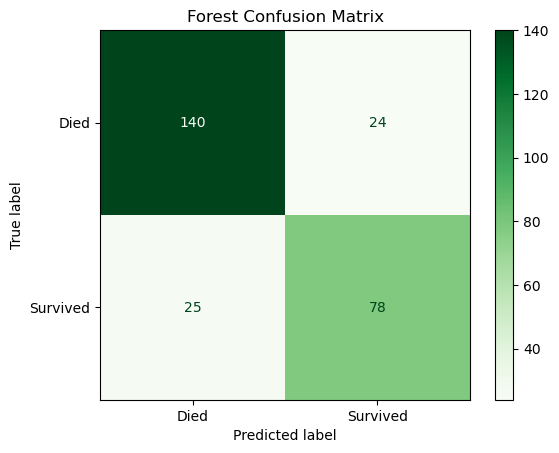

In [43]:
forest_display = ConfusionMatrixDisplay(confusion_matrix(y_test, tuned_forest_pred), display_labels=["Died", "Survived"])
forest_display.plot(cmap=plt.cm.Greens)
plt.title("Forest Confusion Matrix")
plt.savefig("images/forest_confusion_matrix.png", bbox_inches="tight")
plt.show()

## Prediction Function(Forest)

In [44]:
def predict_survival(name, Pclass, Sex, Age, SibSp, PaCh, Fare):
    """
    Predict survival using the tuned Random Forest.
    Sex: 0 = female, 1 = male.
    Returns a message and the probabilities [Died, Survived].
    """
    input_data = pd.DataFrame({
        'Pclass': [Pclass],
        'Sex': [Sex],
        'Age': [Age],
        'SibSp': [SibSp],
        'PaCh': [PaCh],
        'Fare': [Fare],
    })

    prediction = best_forest_model.predict(input_data)[0]
    probabilities = best_forest_model.predict_proba(input_data)[0]

    if prediction == 0:
        result = f'Wooo 😮 {name.title()}, you Died 😢 '
    else:
        result = f'Cheers 🥂 {name.title()}, you Survived 😁 '

    return result, probabilities

In [45]:
print(predict_survival("Tomi", Pclass=1, Age=25.0, SibSp=0, PaCh=0, Fare=100, Sex=1,))

('Cheers 🥂 Tomi, you Survived 😁 ', array([0.47520905, 0.52479095]))


## Support Vector Machine(svm)

In [46]:
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])
svm_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'


In [47]:
svm_prediction = svm_model.predict(X_test)

svm_accuracy = accuracy_score(
    y_test,
    svm_prediction
)
print("SVM Accuracy", svm_accuracy)

SVM Accuracy 0.8089887640449438


In [48]:
print(classification_report(y_test, svm_prediction))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       164
           1       0.80      0.68      0.73       103

    accuracy                           0.81       267
   macro avg       0.81      0.78      0.79       267
weighted avg       0.81      0.81      0.81       267



In [49]:
svm_train_pred = svm_model.predict(X_train)
svm_train_acc = accuracy_score(y_train, svm_train_pred)
print("SVM Training Accuracy", svm_train_acc)

SVM Training Accuracy 0.8467741935483871


## Tuning the Model

In [50]:
svm_params = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1],
    "model__kernel": ["linear", "rbf"]
}
svm_grid = GridSearchCV(
    svm_model,
    svm_params,
    cv=5,
    scoring="accuracy"
)
svm_grid.fit(X_train, y_train)

,estimator,"Pipeline(step...del', SVC())])"
,param_grid,"{'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 0.01, ...], 'model__kernel': ['linear', 'rbf']}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [51]:
print(svm_grid.best_params_)
print(svm_grid.best_score_)

{'model__C': 10, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
0.8370967741935484


In [52]:
best_svm_model = svm_grid.best_estimator_

tuned_svm_pred = best_svm_model.predict(X_test)

tuned_svm_acc = accuracy_score(
    y_test,
    tuned_svm_pred
)
print("Best Accuracy", tuned_svm_acc)

Best Accuracy 0.7790262172284644


In [53]:
print(classification_report(y_test, tuned_svm_pred))

              precision    recall  f1-score   support

           0       0.83      0.81      0.82       164
           1       0.71      0.73      0.72       103

    accuracy                           0.78       267
   macro avg       0.77      0.77      0.77       267
weighted avg       0.78      0.78      0.78       267



In [54]:
confusion_matrix(y_test, tuned_svm_pred)

array([[133,  31],
       [ 28,  75]])

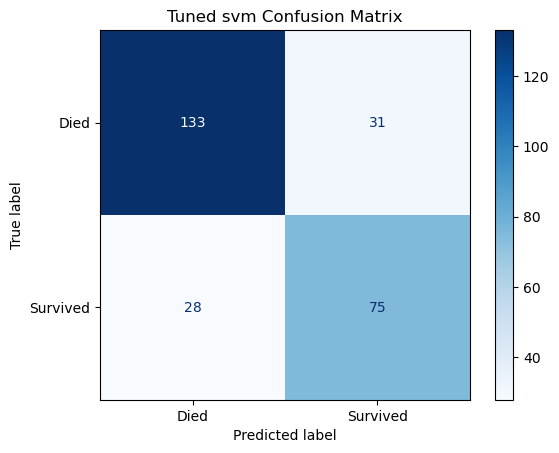

In [55]:
tuned_svm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, tuned_svm_pred), display_labels=['Died', 'Survived'])
tuned_svm_display.plot(cmap=plt.cm.Blues)
plt.title("Tuned svm Confusion Matrix")
plt.savefig("images/tuned_svm_confusion_matrix.png", bbox_inches="tight")
plt.show()

## Comparing their Accuracy

In [56]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression (default)",
        "Logistic Regression (tuned)",
        "Decision Tree (max_depth=3)",
        "Decision Tree (tuned)",
        "Random Forest (max_depth=5)",
        "Random Forest (tuned)",
        "SVM (default)",
        "SVM (tuned)"
    ],
    "CV Accuracy (%)": [
        None,
        log_grid.best_score_ * 100,
        None,
        tree_grid.best_score_ * 100,
        None,
        forest_grid.best_score_ * 100,
        None,
        svm_grid.best_score_ * 100
    ],
    "Test Accuracy (%)": [
        accuracy * 100,
        log_accuracy * 100,
        tree_accuracy * 100,
        tuned_tree_accuracy * 100,
        forest_accuracy * 100,
        tuned_forest_accuracy * 100,
        svm_accuracy * 100,
        tuned_svm_acc * 100
    ]
})

results.round(2)

,Model,CV Accuracy (%),Test Accuracy (%)
0,Logistic Regression (default),NaN,77.90
1,Logistic Regression (tuned),81.77,77.90
2,Decision Tree (max_depth=3),NaN,83.15
3,Decision Tree (tuned),82.58,76.78
4,Random Forest (max_depth=5),NaN,82.77
5,Random Forest (tuned),82.42,81.65
6,SVM (default),NaN,80.90
7,SVM (tuned),83.71,77.90


CV accuracy comes from 5-fold cross-validation on the training set. Models without a CV score were set by hand, not tuned.

## Prediction Function(svm)

In [57]:
input_data = pd.DataFrame([[1, 0, 25.0, 0, 0, 12]], columns=X.columns)
svm_model.predict(input_data)

array([1])